# Notebook to create Figure S6

In [1]:
# CRAN packages 
cran_packages <- c("ggplot2", "dplyr", "glue", "purrr")

for (pkg in cran_packages) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    install.packages(pkg)
  } else {
    message(glue::glue("Already installed package: {pkg}"))
  }
  library(pkg, character.only = TRUE) 
}

Already installed package: ggplot2

Already installed package: dplyr


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Already installed package: glue

Already installed package: purrr



In [2]:
sequences_group <- 'bacteria_1'
path <- "../../Results/RDPG/embeddings_comparison_results"
output_dir <- ""

In [3]:
color_dict = c(
  "dna2vec & TNF" = "#006e82",
  "TNF & DNABERT-2" = "#8214a0",
  "TNF & DNABERT-S" = "#005ac8",
  "TNF & HyenaDNA" = "darkgreen",
  "DNABERT-2 & dna2vec" = "#aa0a3c",
  "dna2vec & DNABERT-S" = "#9abc1d",
  "dna2vec & HyenaDNA" = "#fa7850",
  "DNABERT-S & DNABERT-2" = "#14d2dc",
  "HyenaDNA & DNABERT-2" = "#ffde59",
  "HyenaDNA & DNABERT-S" = "#fa78fa"
)

## 1. Evolution of RDPG test p-values depending on hyperparameter k

In [4]:
organize_k_exploration_pvalues <- function(comp_results_dir, sequences_group, k_values) {
  
  dfs <- list()
  
  for (k in k_values) {
    file_name <- paste0("data_for_k_exploration_euclidean_KNN_k-", k, "_d-0")
    dfs[[as.character(k)]] <- read.table(glue("../../Results/RDPG/{sequences_group}_{file_name}.tsv"), sep = '\t',  header = T)
  }
  
  results <- list()
  
  for (k in names(dfs)) {
    df <- dfs[[k]]
    
    res <- df %>%
      group_by(`Seq.ID`, `Models.compared`) %>%
      slice_min(order_by = `p.value`, n = 1, with_ties = FALSE) %>%
      ungroup() %>%
      mutate(k = as.numeric(k))
    
    results[[k]] <- res
  }
  
  final_result <- bind_rows(results)
  
  k_median_df <- final_result %>%
    group_by(`Models.compared`, k) %>%
    summarise(`p-value` = median(`p.value`), .groups = "drop")
  
  k_mean_df <- final_result %>%
    group_by(`Models.compared`, k) %>%
    summarise(`p-value` = mean(`p.value`), .groups = "drop")
  
  list(
    final_result = final_result,
    k_median_df = k_median_df,
    k_mean_df = k_mean_df
  )
}

In [5]:
k_values <- c(5, 10, 25, 40, 55, 70)

In [6]:
result <- organize_k_exploration_pvalues(
  path,
  sequences_group,
  k_values
)

k_median_pvals_df  <- result$k_median_df

In [7]:
k_median_pvals_df <- 
  k_median_pvals_df %>%
  mutate(Models.pretty = recode(Models.compared,
    "dna2vec & tnf" = "dna2vec & TNF",
    "dnabert2 & tnf" = "TNF & DNABERT-2",
    "dnaberts & tnf" = "TNF & DNABERT-S",
    "hyenadna & tnf" = "TNF & HyenaDNA",
    "dna2vec & dnabert2" = "DNABERT-2 & dna2vec",
    "dna2vec & dnaberts" = "dna2vec & DNABERT-S",
    "dna2vec & hyenadna" = "dna2vec & HyenaDNA",
    "dnabert2 & dnaberts" = "DNABERT-S & DNABERT-2",
    "dnabert2 & hyenadna" = "HyenaDNA & DNABERT-2",
    "dnaberts & hyenadna" = "HyenaDNA & DNABERT-S"
  ))

## 2. Evolution of Jaccard distances depending on hyperparameter k 

In [8]:
setwd("../../Results/Jaccard_distance/bacteria_1/jaccard_results")
jaccard_similarities_files <- list.files(pattern = glue("*_jaccard_similarity_k-*"), ignore.case = TRUE)
jaccard_similarities_files

[1] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-10.csv" 
 [2] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-25.csv" 
 [3] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-40.csv" 
 [4] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-5.csv"  
 [5] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-55.csv" 
 [6] "bacteria_1_dnabert2_dna2vec_jaccard_similarity_k-70.csv" 
 [7] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-10.csv" 
 [8] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-25.csv" 
 [9] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-40.csv" 
[10] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-5.csv"  
[11] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-55.csv" 
[12] "bacteria_1_dnaberts_dna2vec_jaccard_similarity_k-70.csv" 
[13] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-10.csv"
[14] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-25.csv"
[15] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-40.csv"
[16] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-5.csv" 
[17] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-55.csv"
[18] "bacteria_1_dnaberts_dnabert2_jaccard_similarity_k-70.csv"
[19] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-10.csv"     
[20] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-25.csv"     
[21] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-40.csv"     
[22] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-5.csv"      
[23] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-55.csv"     
[24] "bacteria_1_dnaberts_tnf_jaccard_similarity_k-70.csv"     
[25] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-10.csv" 
[26] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-25.csv" 
[27] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-40.csv" 
[28] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-5.csv"  
[29] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-55.csv" 
[30] "bacteria_1_hyenadna_dna2vec_jaccard_similarity_k-70.csv" 
[31] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-10.csv"
[32] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-25.csv"
[33] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-40.csv"
[34] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-5.csv" 
[35] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-55.csv"
[36] "bacteria_1_hyenadna_dnabert2_jaccard_similarity_k-70.csv"
[37] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-10.csv"
[38] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-25.csv"
[39] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-40.csv"
[40] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-5.csv" 
[41] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-55.csv"
[42] "bacteria_1_hyenadna_dnaberts_jaccard_similarity_k-70.csv"
[43] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-10.csv"     
[44] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-25.csv"     
[45] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-40.csv"     
[46] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-5.csv"      
[47] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-55.csv"     
[48] "bacteria_1_hyenadna_tnf_jaccard_similarity_k-70.csv"     
[49] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-10.csv"      
[50] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-25.csv"      
[51] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-40.csv"      
[52] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-5.csv"       
[53] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-55.csv"      
[54] "bacteria_1_tnf_dna2vec_jaccard_similarity_k-70.csv"      
[55] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-10.csv"     
[56] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-25.csv"     
[57] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-40.csv"     
[58] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-5.csv"      
[59] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-55.csv"     
[60] "bacteria_1_tnf_dnabert2_jaccard_similarity_k-70.csv"

In [9]:
results_list <- list()

for (file in jaccard_similarities_files) {
  jaccard_similarities <- read.table(file, header = TRUE, sep = '\t')
  jaccard_distances <- 1 - jaccard_similarities
  median_jaccard_distance <- median(t(jaccard_distances)[,1])
  
  k <- as.numeric(sub(".*k-([0-9]+)\\.csv", "\\1", file))
  
  models_part <- sub(".*_1_", "", file)
  models_part <- sub("_jaccard_similarity.*", "", models_part)
  
  models_compared <- gsub("_", " & ", models_part)

  results_list[[length(results_list) + 1]] <- data.frame(
    Models_compared = models_compared,
    k = k,
    Jaccard_distance = median_jaccard_distance
  )
}

results_df <- do.call(rbind, results_list)

In [10]:
results_df <- 
  results_df %>%
  mutate(Models.pretty = recode(Models_compared,
    "tnf & dna2vec"   = "dna2vec & TNF",
    "tnf & dnabert2"  = "TNF & DNABERT-2",
    "dnaberts & tnf"  = "TNF & DNABERT-S",
    "hyenadna & tnf"  = "TNF & HyenaDNA",
    "dnabert2 & dna2vec"   = "DNABERT-2 & dna2vec",
    "dnaberts & dna2vec"   = "dna2vec & DNABERT-S",
    "hyenadna & dna2vec"   = "dna2vec & HyenaDNA",
    "dnaberts & dnabert2"  = "DNABERT-S & DNABERT-2",
    "hyenadna & dnabert2"  = "HyenaDNA & DNABERT-2",
    "hyenadna & dnaberts"  = "HyenaDNA & DNABERT-S"
  ))

## 3. Join results to generate the plot

In [11]:
df1 <- results_df[results_df$k <= 70,] %>%
  rename(value = Jaccard_distance,
         Models.compared = Models_compared) %>%
  mutate(metric = "Jaccard distances")

df2 <- k_median_pvals_df %>%
  rename(value = `p-value`) %>%
  mutate(metric = "RDPG p-values")

df_combined <- bind_rows(df1, df2)

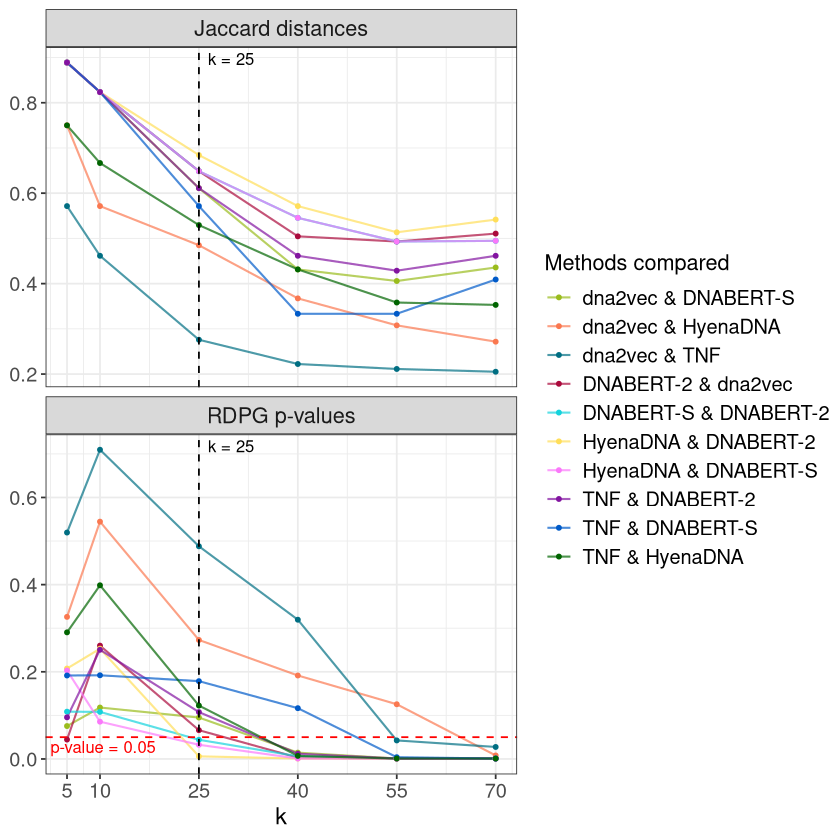

In [12]:
p <- ggplot(df_combined, aes(x = k, y = value,
               color = Models.pretty,
               group = Models.pretty)) +
  geom_line(linewidth = 0.6, alpha = 0.7) +
  geom_point(size = 1) +

  geom_vline(xintercept = 25,
             linetype = "dashed",
             color = "black",
             linewidth = 0.5) +

  geom_hline(
  data = df_combined %>% dplyr::filter(metric == "RDPG p-values"),
  aes(yintercept = 0.05),
  linetype = "dashed",
  color = "red",
  linewidth = 0.5
) +

  facet_wrap(~metric, ncol = 1, scales = "free_y") +

  theme_bw() +
  theme(
  axis.title = element_text(size = 14),
  axis.text = element_text(size = 12),
  legend.text = element_text(size = 12),
  legend.title = element_text(size = 13),
  strip.text = element_text(size = 13)
) +
  labs(
    x = "k",
    y = NULL,
    color = "Methods compared"
  ) +
  scale_color_manual(values = color_dict) +
  scale_x_continuous(breaks = c(5, 10, 25, 40, 55, 70, 85, 100))


p <- p +
  annotate("text",
           x = 25, y = Inf,
           label = "k = 25",
           color = "black",
           hjust = -0.2, vjust = 1.5,
           size = 3.5) +
  geom_text(
    data = df_combined %>% dplyr::filter(metric == "RDPG p-values") %>% dplyr::slice(1),
    aes(x = 20, y = 0, label = "p-value = 0.05"),
    inherit.aes = FALSE,
    color = "red",
    hjust = 1.1, vjust = -0.5,
    size = 3.5
  )

p

In [16]:
ggsave("../../../Plots/median_of_jacc_dist_and_pvalues_depending_on_k_5_to_70_figure_S6.png", plot = p, width = 8, height = 7, dpi = 500)